In [1]:
from google.colab import drive;
drive.mount('/content/drive');

Mounted at /content/drive


In [2]:
def customize_tabel(data):
    res = data.style.set_table_styles([
        {'selector': 'thead th',
        'props': [('background-color', "#DF5ED4"), ('color', 'white'), ('font-weight', 'bold'), ('border', '1px solid white'), ('text-align', 'left')]},

        {'selector': 'tbody td',
        'props': [('background-color', '#202124'), ('color', 'white'), ('border', '1px solid white'), ('text-align', 'left')]}
    ]).hide(axis='index');
    return res;

In [3]:
import glob;
import pandas as pds;
import seaborn as sns;
import matplotlib.pyplot as plt;

hasil_joins = glob.glob('/content/drive/**/*joins_sp_LC.csv', recursive=True);
hasil_igs = glob.glob('/content/drive/**/*igs_sp_LC.csv', recursive=True);

print(hasil_joins);
print(hasil_igs);

file_joins = hasil_joins[0];
file_igs = hasil_igs[0];

df_joins = pds.read_csv(file_joins, low_memory=False);
df_igs = pds.read_csv(file_igs, low_memory=False);

df_pre_project = df_joins.drop_duplicates('nfireID2').copy();

batas_rendah, batas_tinggi = df_pre_project['FRP_Days'].quantile([1/3, 2/3]);

def three_class(row):
    if pds.isna(row['FRP_Days']):
        return 'NO_CLASS';
    elif row['FRP_Days'] <= batas_rendah:
        return 'RENDAH';
    elif row['FRP_Days'] <= batas_tinggi:
        return 'SEDANG';
    else:
        return 'TINGGI';

df_pre_project['Class'] = df_pre_project.apply(three_class, axis=1);

['/content/drive/MyDrive/dataset ka/nfire4_all_spatial_fire_2002_2019_joins_sp_LC.csv']
['/content/drive/MyDrive/dataset ka/nfire4_all_spatial_fire_2002_2019_igs_sp_LC.csv']


In [4]:
ringkasan = pds.DataFrame({
    'dataset': ['joins', 'igs', 'df_pre_project (satu baris per kejadian)'],
    'baris': [df_joins.shape[0], df_igs.shape[0], df_pre_project.shape[0]],
    'kolom': [df_joins.shape[1], df_igs.shape[1], df_pre_project.shape[1]]
});
display(customize_tabel(ringkasan));

batas = pds.DataFrame({
    'batas': ['persentil ke-33,3', 'persentil ke-66,7'],
    'nilai FRP_Days': [round(batas_rendah, 2), round(batas_tinggi, 2)]
});
display(customize_tabel(batas));

dataset,baris,kolom
joins,1232377,49
igs,720795,31
df_pre_project (satu baris per kejadian),484366,50


batas,nilai FRP_Days
"persentil ke-33,3",14.000000
"persentil ke-66,7",41.600000


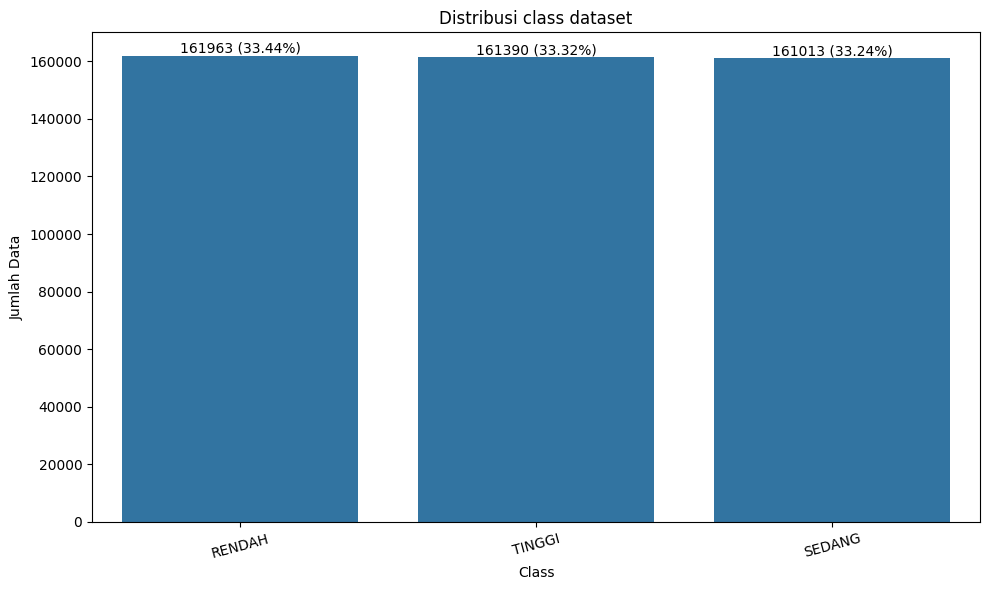

class,count,percent
RENDAH,161963,33.438144
TINGGI,161390,33.319845
SEDANG,161013,33.242011


Missing Class: 0


,count
Class,
RENDAH,161963
TINGGI,161390
SEDANG,161013


In [5]:
class_counts = df_pre_project['Class'].value_counts();
percent = (class_counts / len(df_pre_project)) * 100;

plt.figure(figsize=(10, 6));
ax = sns.barplot(x=class_counts.index, y=class_counts.values);

for i, bar in enumerate(ax.patches):
    height = bar.get_height();
    ax.annotate(
        f'{int(height)} ({percent.iloc[i]:.2f}%)',
        (bar.get_x() + bar.get_width() / 2, height),
        ha='center',
        va='bottom'
    );

plt.title('Distribusi class dataset');
plt.xlabel('Class');
plt.ylabel('Jumlah Data');
plt.xticks(rotation=15);
plt.tight_layout();
plt.show();

data = pds.DataFrame({
    'class': class_counts.index,
    'count': class_counts.values,
    'percent': percent.values
});
display(customize_tabel(data));
print("Missing Class:", df_pre_project['Class'].isna().sum());
display(class_counts);